# Notebook 1: Bill analysis (`history/last_month/bill.csv`)

In this notebook I look at last month's compute bill. I want to understand how much we spent, which machines the money went to, and whether the spending changed when the query traffic changed.

This matters for the scheduler because the assignment scores it using this formula:

```
profit = revenue - compute cost - SLA miss penalties (after caps) - drop penalties
```

Compute cost is the part of the formula that the scheduler controls most directly, because it decides how many machines to rent, which types, and in which market. Before designing anything, I needed to know how big this cost was and what was driving it.

To understand what the file contains, I checked the simulator source. `simkit/engine.py` writes `bill.csv` in `_write_outputs`. Every time a machine's billing segment is closed, `_bill_add` splits the billed time at day boundaries (`day = int(t // 86400)`) and adds the following to the row for `(day, instance_type, market)`:

- `cost_usd += seconds * price_per_second`
- `instance_hours += seconds / 3600`

This means that each row is one simulation day, for one machine type, in one market. The costs are exact per-second charges, plus the 60-second billing minimum for machines that run for less than a minute.

The notebook is organised as follows:

1. Setup and loading
2. Structure and data quality
3. Totals and reconciliation
4. Spending by machine type and market
5. Daily spending over the month
6. Did the bill respond to traffic? (uses the query log only for daily arrival counts)
7. Unusual patterns and conclusions

## 1. Setup and loading

In this step I import the libraries, find the data folder and set one chart style for the whole notebook.

I wanted the notebook to run on its own, whether it is started from the project root or from the `analysis/` folder. Instead of hard-coding a path, I wrote a helper, `find_history_dir()`, that walks up from the current folder until it finds `history/last_month/`. This way it does not matter where Jupyter was started.

The libraries I use are:

- `pandas` for tables (DataFrames), grouping and totals.
- `numpy` for number helpers.
- `matplotlib` for charts.
- `json` and `pathlib` from the standard library, for reading the config and handling paths.

I also gave each machine type a fixed colour that I reuse in every notebook, so `mem.xlarge` always looks the same in the charts.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)


def find_history_dir() -> Path:
    """Return the history/last_month folder, searching upwards from the working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "history" / "last_month"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find history/last_month. Run this notebook from the project "
                            "folder or from analysis/.")


HISTORY_DIR = find_history_dir()

# Fixed colours per machine type (same in every notebook)
TYPE_ORDER = ["std.small", "std.large", "mem.xlarge"]
TYPE_COLORS = {"std.small": "#2a78d6", "std.large": "#eb6834", "mem.xlarge": "#1baf7a"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold", "lines.linewidth": 2,
})
print("History folder:", HISTORY_DIR.resolve())
print("Files:", sorted(p.name for p in HISTORY_DIR.iterdir()))

History folder: /home/claude/scheduler-takehome/history/last_month
Files: ['bill.csv', 'config.json', 'fleet_timeseries.csv', 'instance_log.csv', 'query_log.csv.gz']


The output shows where the data was found and lists the five historical files. If this cell fails, it means the notebook was started outside the project, and nothing else will work until the path is fixed.

All five files are there, so I can load `bill.csv`.

### 1.1 Load the bill and the pricing config

Here I read `bill.csv` into a DataFrame, and I also read `config.json` so that I can check the bill against the official hourly prices.

I need the config because the bill on its own only tells me *what* was charged. To check that the charges are correct, I compare each row with `instance_hours * hourly price` from the config. By design, the simulator should match this exactly.

In [2]:
bill = pd.read_csv(HISTORY_DIR / "bill.csv")
with open(HISTORY_DIR / "config.json") as f:
    config = json.load(f)

bill.head(8)

,day,instance_type,market,instance_hours,cost_usd
0,0,mem.xlarge,on_demand,144.0000,391.6800
1,0,std.large,on_demand,144.0000,97.9200
2,0,std.small,on_demand,48.0000,4.8000
3,1,mem.xlarge,on_demand,144.0000,391.6800
4,1,std.large,on_demand,144.0000,97.9200
5,1,std.small,on_demand,48.0000,4.8000
6,2,mem.xlarge,on_demand,144.0000,391.6800
7,2,std.large,on_demand,144.0000,97.9200


Each row is one day (`day` = 0, 1, 2 ..., counted from the start of the simulation), one machine type and one market (`on_demand` or `spot`). It shows the machine-hours billed that day and their cost in dollars.

The first thing I noticed was that on day 0, `mem.xlarge` has 144 instance-hours. A day has 24 hours, so 144 / 24 = 6 machines ran for the whole day. In the same way, 144 hours of `std.large` means 6 machines, and 48 hours of `std.small` means 2 machines. I check this properly below instead of relying on the first few rows.

## 2. Structure and data quality

Before using the data, I checked the shape of the table, the column types, missing values and duplicates.

Every number later in the notebook is a sum over these rows. If a row were duplicated, the bill would look bigger than it really was. If a value were missing, it would be silently skipped in the sums. So I wanted to rule these out before trusting any total.

The important columns are:

- `day`: the day number, calculated as `day = floor(t / 86400)`, where `t` is the number of seconds since the simulation started.
- `instance_type` and `market`: what was rented.
- `instance_hours`: the billed machine time (not slot time).
- `cost_usd`: the dollars charged.

In this table, a duplicate means two rows with the same `(day, instance_type, market)`, because that is exactly the key the simulator uses to group the charges.

In [3]:
print("Rows, columns:", bill.shape)
print("\nData types:")
print(bill.dtypes)
print("\nMissing values per column:")
print(bill.isna().sum())
key = ["day", "instance_type", "market"]
print("\nFully duplicated rows:", bill.duplicated().sum())
print("Duplicated (day, instance_type, market) keys:", bill.duplicated(subset=key).sum())
print("\nDays present:", bill["day"].min(), "to", bill["day"].max(), f"({bill['day'].nunique()} distinct)")
print("Instance types:", sorted(bill["instance_type"].unique()))
print("Markets:", sorted(bill["market"].unique()))

Rows, columns: (93, 5)

Data types:
day                 int64
instance_type         str
market                str
instance_hours    float64
cost_usd          float64
dtype: object

Missing values per column:
day               0
instance_type     0
market            0
instance_hours    0
cost_usd          0
dtype: int64

Fully duplicated rows: 0
Duplicated (day, instance_type, market) keys: 0

Days present: 0 to 30 (31 distinct)
Instance types: ['mem.xlarge', 'std.large', 'std.small']
Markets: ['on_demand']


The table has 93 rows and 5 columns. There are 31 days, 3 machine types and 1 market, and 31 \* 3 \* 1 = 93, so there is exactly one row per day for each machine type.

The column types make sense: integers for `day`, decimals for hours and cost, and text for the categories. There are no missing values and no duplicate keys, so I can trust the sums below.

Two things stood out to me:

- **Only the `on_demand` market appears.** No spot machines were rented last month. This becomes important later, because it means the history cannot tell us anything about spot interruptions.
- **There are 31 days (0 to 30), not 30.** The contract month is 30 days (`duration_s = 2,592,000 s` in the config), so day 30 must be a partial day after the official end. I look into this in Section 5.

### 2.1 Descriptive statistics

Next I used `describe()`. For each numeric column, it gives the count, the mean (average), the standard deviation (how spread out the values are around the mean), the minimum, the quartiles and the maximum.

This is a quick way to spot values that should not be possible, such as negative costs, or values that are suspiciously all the same. The quartiles split the rows into four groups: 25% of rows are below the 25% value, half are below the median (50%), and 75% are below the 75% value.

I describe each machine type separately. Mixing a \$0.10/hr machine with a \$2.72/hr machine in one summary would hide the pattern.

In [4]:
bill.groupby("instance_type")[["instance_hours", "cost_usd"]].describe().T

instance_type         mem.xlarge  std.large  std.small
instance_hours count     31.0000    31.0000    31.0000
               mean     139.8387   139.8387    46.6129
               std       23.1691    23.1691     7.7230
               min       15.0000    15.0000     5.0000
               25%      144.0000   144.0000    48.0000
               50%      144.0000   144.0000    48.0000
               75%      144.0000   144.0000    48.0000
               max      144.0000   144.0000    48.0000
cost_usd       count     31.0000    31.0000    31.0000
               mean     380.3613    95.0903     4.6613
               std       63.0199    15.7550     0.7723
               min       40.8000    10.2000     0.5000
               25%      391.6800    97.9200     4.8000
               50%      391.6800    97.9200     4.8000
               75%      391.6800    97.9200     4.8000
               max      391.6800    97.9200     4.8000

For each machine type, I looked at the `min`, `25%`, `50%` and `75%` rows of `instance_hours`. They are all the same (144 for `mem.xlarge` and `std.large`, and 48 for `std.small`), except for the minimum, which is the partial day 30. The standard deviation is small compared with the mean, and it only comes from that one short day. This means the number of machines never changed during the month.

So the fleet was fixed. Machines were never added at busy times or removed at quiet times.

This table on its own cannot tell me *why* the fleet was fixed. However, the README says production ran "a fixed set of on-demand machines", and `simkit/baselines.py` has a `LegacyStatic` scheduler with `FLEET = {"std.small": 2, "std.large": 6, "mem.xlarge": 6}`, which matches what I see here.

## 3. Totals and reconciliation

In this section I calculate the total compute spending for the month and the total billed instance-hours. I also check whether every row matches the config prices.

The total answers Part 1 question 1 ("What did we spend?"). The reconciliation is a check on my own understanding of how the bill is built. If `cost_usd != instance_hours * hourly price`, then either the bill contains something else, such as price changes or the billing minimum, or I have misunderstood how it works.

I used these formulas:

- `total_cost = sum(cost_usd)` over all rows
- `total_instance_hours = sum(instance_hours)`
- `expected_cost_row = instance_hours * price_per_hour(instance_type, market)`, where the price comes from `config["instance_types"][type]["on_demand_usd_per_hr"]` (or `spot_usd_per_hr` for spot).

I allow a small tolerance of `1e-3` dollars, because the CSV stores rounded values (3 decimals for hours and 4 for cost).

In [5]:
def hourly_price(instance_type: str, market: str) -> float:
    spec = config["instance_types"][instance_type]
    return spec["on_demand_usd_per_hr"] if market == "on_demand" else spec["spot_usd_per_hr"]


bill["price_per_hr"] = [hourly_price(t, m) for t, m in zip(bill["instance_type"], bill["market"])]
bill["expected_cost_usd"] = bill["instance_hours"] * bill["price_per_hr"]
bill["reconciliation_diff"] = bill["cost_usd"] - bill["expected_cost_usd"]

total_cost = bill["cost_usd"].sum()
total_hours = bill["instance_hours"].sum()
print(f"Total compute cost:          ${total_cost:,.2f}")
print(f"Total billed instance-hours: {total_hours:,.1f} h")
print(f"Average price per instance-hour: ${total_cost / total_hours:,.4f}")
print(f"Largest |row difference| vs config price: ${bill['reconciliation_diff'].abs().max():.6f}")
assert bill["reconciliation_diff"].abs().max() < 1e-3, "A bill row does not match config prices"
print("Check passed: every row equals instance_hours × config hourly price.")

Total compute cost:          $14,883.50
Total billed instance-hours: 10,115.0 h
Average price per instance-hour: $1.4714
Largest |row difference| vs config price: $0.000000
Check passed: every row equals instance_hours × config hourly price.


**Total compute spending was \$14,883.50** for the simulated period, across **10,115 instance-hours**. One instance-hour is one machine running for one hour, no matter how many slots it has or whether it did any work.

The average price works out to about \$1.47 per instance-hour. This number does not mean much on its own, because it mixes three very different machine prices. I only show it as a sanity check.

Every row equals hours \* config price, up to rounding. This tells me that there were **no price changes during the month and no billing-minimum charges**. The minimum only applies to machines that run for less than 60 seconds.

What the bill cannot tell me is whether those hours were useful. An idle machine is billed exactly the same as a busy one. I look at utilisation in Notebook 2.

## 4. Spending by machine type and market

Here I look at how the total is split across machine types and markets, and what share of the bill each type takes.

If one machine type takes most of the bill, that is where saving money will matter most. A \$0.10/hr machine can only ever be a small part of it.

I group the rows with `groupby(["instance_type", "market"])` and sum `instance_hours` and `cost_usd`. The share is calculated as `cost / total_cost * 100`. I also calculate two more columns:

- `slot_hours = instance_hours * slots_per_machine`: how much *query-running capacity* we paid for. One slot runs one query at a time.
- `cost_per_slot_hour = hourly price / slots_per_machine`: the price of one slot for one hour. This makes machines of different sizes easier to compare.

In [6]:
by_type = (bill.groupby(["instance_type", "market"], as_index=False)[["instance_hours", "cost_usd"]].sum())
by_type["share_of_bill_pct"] = by_type["cost_usd"] / total_cost * 100
by_type["price_per_hr"] = [hourly_price(t, m) for t, m in zip(by_type["instance_type"], by_type["market"])]
by_type["slots_per_machine"] = by_type["instance_type"].map(lambda t: config["instance_types"][t]["slots"])
by_type["slot_hours"] = by_type["instance_hours"] * by_type["slots_per_machine"]
by_type["cost_per_slot_hour"] = by_type["price_per_hr"] / by_type["slots_per_machine"]
by_type = by_type.set_index("instance_type").loc[TYPE_ORDER].reset_index()

assert abs(by_type["cost_usd"].sum() - total_cost) < 1e-6
assert abs(by_type["share_of_bill_pct"].sum() - 100) < 1e-9
by_type

,instance_type,market,instance_hours,cost_usd,share_of_bill_pct,price_per_hr,slots_per_machine,slot_hours,cost_per_slot_hour
0,std.small,on_demand,"1,445.0000",144.5000,0.9709,0.1000,2,"2,890.0000",0.0500
1,std.large,on_demand,"4,335.0000","2,947.8000",19.8058,0.6800,8,"34,680.0000",0.0850
2,mem.xlarge,on_demand,"4,335.0000","11,791.2000",79.2233,2.7200,16,"69,360.0000",0.1700


The split looks like this:

| | Reading |
|---|---|
| `mem.xlarge` | about **79%** of the bill (\$11,791) |
| `std.large` | about **20%** (\$2,948) |
| `std.small` | under **1%** (\$144.50) |

The checks confirm that the three rows add up to the total and the shares add up to 100%.

The `cost_per_slot_hour` column turned out to be useful. `mem.xlarge` costs \$2.72 / 16 = \$0.17 per slot-hour, compared with \$0.085 for `std.large` and \$0.05 for `std.small`. So the big machine is the most expensive *per slot*. It is only worth using when it makes queries fast enough to make up for the higher price. I do that comparison in Notebook 5.

`mem.xlarge` and `std.large` have the same `instance_hours`, because there were 6 machines of each running for the same amount of time. This means the whole cost difference between them comes from the price.

For the scheduler, this shows that the `mem.xlarge` fleet is the biggest cost. Any strategy that keeps six of them running all month will struggle to beat the baselines. There are two ways to bring this cost down: use fewer `mem.xlarge` hours by scaling with demand, or make the hours cheaper by using spot at \$0.95/hr instead of \$2.72/hr, as long as interruptions can be handled.

### 4.1 Market split

Here I compare on-demand and spot spending.

In this config, spot costs roughly a third of the on-demand price, so the choice of market can make a big difference to the bill.

In [7]:
by_market = bill.groupby("market")[["instance_hours", "cost_usd"]].sum()
by_market["share_of_bill_pct"] = by_market["cost_usd"] / total_cost * 100
by_market

,instance_hours,cost_usd,share_of_bill_pct
market,,,
on_demand,"10,115.0000","14,883.5000",100.0000


All of the spending was on-demand. Spot was never used.

This means that last month we paid full price for every hour. It also means I cannot tell how spot would have behaved. There is no spot data in the history at all, so I have to work out spot interruptions from the config (`spot_interruptions_per_hr`, `spot_notice_s`) and the simulator code instead of from past evidence.

### 4.2 Chart: share of the bill by machine type

I used a horizontal bar chart here because, with only three values, it shows the imbalance at a glance. I labelled each bar with its dollar value and share, so the chart can be read without the table.

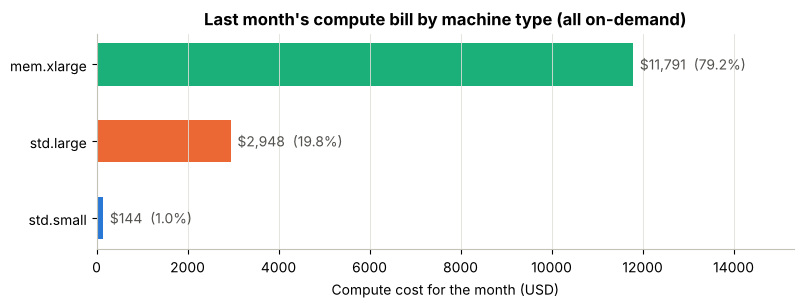

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(by_type["instance_type"], by_type["cost_usd"],
        color=[TYPE_COLORS[t] for t in by_type["instance_type"]], height=0.55)
for y, (cost, pct) in enumerate(zip(by_type["cost_usd"], by_type["share_of_bill_pct"])):
    ax.text(cost + total_cost * 0.01, y, f"${cost:,.0f}  ({pct:.1f}%)", va="center", color="#52514e")
ax.set_xlabel("Compute cost for the month (USD)")
ax.set_title("Last month's compute bill by machine type (all on-demand)")
ax.set_xlim(0, by_type["cost_usd"].max() * 1.3)
ax.grid(axis="y", visible=False)
plt.show()

The length of each bar is in dollars. `mem.xlarge` on its own is about four times the cost of everything else put together.

This is what I observed in the data. It suggests that savings will have to come from `mem.xlarge` capacity, but I still need the utilisation analysis in Notebook 2 to check whether that capacity was actually needed.

## 5. Daily spending throughout the month

In this section I look at spending per day, both overall and by machine type, to see whether it stayed the same throughout the month.

If the scheduler scaled with demand, the bill would go up on busy days and down on quiet days. A flat bill would mean the capacity was fixed regardless of demand.

I pivot the bill into a table with one row per day and one column per machine type (`pivot_table`, summing `cost_usd`), and then add a total column. I also work out how many machines ran each day using `instance_hours / hours_covered_that_day`.

Each `day d` covers the elapsed seconds `[d * 86400, (d+1) * 86400)`. The README says `t = 0` is Monday 00:00 US/Eastern, so day 0 is a Monday, day 5 is a Saturday, and so on. I only use this to label the days, because the bill itself has no calendar information.

In [9]:
daily = bill.pivot_table(index="day", columns="instance_type", values="cost_usd", aggfunc="sum")[TYPE_ORDER]
daily["total"] = daily.sum(axis=1)
daily_hours = bill.pivot_table(index="day", columns="instance_type", values="instance_hours", aggfunc="sum")[TYPE_ORDER]

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
daily.insert(0, "weekday", [WEEKDAYS[d % 7] for d in daily.index])

assert abs(daily["total"].sum() - total_cost) < 1e-6, "Daily totals do not add up to the bill"
print("Distinct daily totals (rounded to cents):")
print(daily["total"].round(2).value_counts())
daily.tail(4)

Distinct daily totals (rounded to cents):
total
494.4000    30
51.5000      1
Name: count, dtype: int64


instance_type,weekday,std.small,std.large,mem.xlarge,total
day,,,,,
27,Sun,4.8000,97.9200,391.6800,494.4000
28,Mon,4.8000,97.9200,391.6800,494.4000
29,Tue,4.8000,97.9200,391.6800,494.4000
30,Wed,0.5000,10.2000,40.8000,51.5000


**Days 0 to 29 each cost exactly \$494.40.** That is `24 h * (2 * $0.10 + 6 * $0.68 + 6 * $2.72) = 24 * $20.60`.

**Day 30 cost \$51.50**, which is `2.5 h * $20.60`. This means the fleet kept running for 2.5 hours after the 30-day mark. The check also confirms that the daily totals add up to the monthly total.

I wanted to understand why there is a day 30 at all. In the main loop of `engine.py`, the simulation only stops when `nxt is None and not self.active and self.now >= self.duration`. In other words, it stops when there are no more arrivals **and no unfinished queries**. Some queries arrived just before the 30-day mark, for example long `report` or `adhoc` jobs, and they were still running or waiting. So the simulation carried on, and the fixed fleet was billed until it ended at `t = 2,601,000 s`, which is 9,000 seconds (2.5 hours) past the end.

This is not a data error. It is a real cost of the month. A scheduler that shuts machines down once the work runs out would have paid less for this tail.

### 5.0 How many machines ran each day?

Here I work out how many machines of each type were running each day, based on the instance-hours.

In theory, a constant daily cost could hide changes that cancel each other out, for example one machine type going up while another goes down. Turning the hours into machine counts for each type rules this out.

I use `machines(day, type) = instance_hours(day, type) / hours_covered(day)`. On a full day, `hours_covered = 24`. For the partial last day, I work out `hours_covered` from the data instead of assuming it.

In [10]:
# How many machines were running each day?
# On a full day (24 h) the machine count is total instance-hours / 24.
# The last day is partial, so first find how many hours it covered:
#   hours_covered(day) = total instance-hours that day / machine count on a full day
# (valid because the machine count is constant, which the min/max check below confirms).
full_day_machine_count = daily_hours.loc[0].sum() / 24
hours_covered = daily_hours.sum(axis=1) / full_day_machine_count
machines_per_day = daily_hours.div(hours_covered, axis=0)
print(f"Machines on a full day: {full_day_machine_count:.0f}")
print("Implied machine count per type (min / max over all days):")
print(machines_per_day.agg(["min", "max"]).round(3))
print("\nHours covered on the last day:", round(hours_covered.iloc[-1], 3))

Machines on a full day: 14
Implied machine count per type (min / max over all days):
instance_type  std.small  std.large  mem.xlarge
min               2.0000     6.0000      6.0000
max               2.0000     6.0000      6.0000

Hours covered on the last day: 2.5


The machine count is the same every day, including the partial day 30: 2 `std.small`, 6 `std.large` and 6 `mem.xlarge`, which is 14 machines in total. The last day covered 2.5 hours.

So the size of the fleet never changed. Spending depended only on time, not on the amount of work.

### 5.1 Chart: daily spending by machine type

I used one stacked bar per day so the chart shows both the daily total and what it is made of. If the fleet had scaled, the bar heights would vary. I left a thin white gap between the stacked pieces so each one is easy to see.

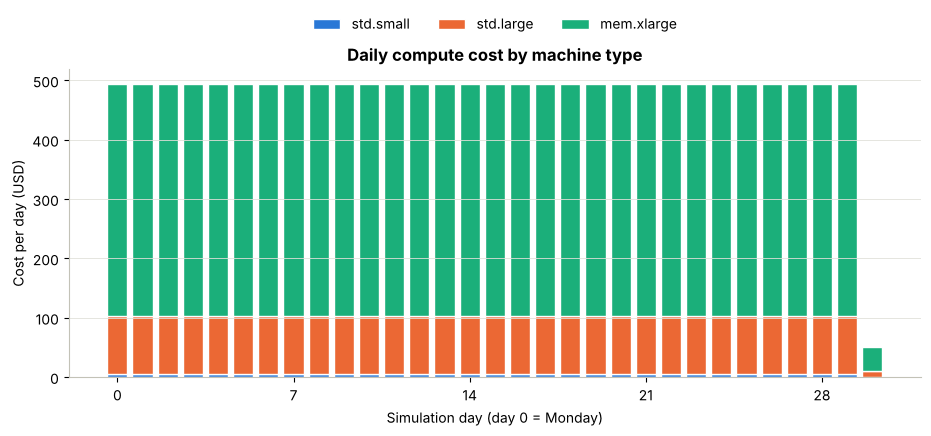

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(daily))
for t in TYPE_ORDER:
    ax.bar(daily.index, daily[t], bottom=bottom, color=TYPE_COLORS[t], label=t,
           width=0.8, edgecolor="white", linewidth=1)
    bottom += daily[t].to_numpy()
ax.set_xlabel("Simulation day (day 0 = Monday)")
ax.set_ylabel("Cost per day (USD)")
ax.set_title("Daily compute cost by machine type")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), frameon=False, ncol=3)
ax.set_ylim(0, daily["total"].max() * 1.05)
ax.set_xticks(range(0, 31, 7))
ax.grid(axis="x", visible=False)
plt.show()

Every full day has the same height and the same mix of machine types. The only exception is the short bar for day 30, which is the 2.5-hour tail. There is no weekly pattern in the spending.

## 6. Did spending respond to query traffic?

This is the main question for this notebook: did the bill stay the same while the traffic changed?

If traffic varies a lot, for example if weekends are much quieter, but spending stays flat, then the fleet was too big at quiet times, too small at busy times, or both.

The bill does not contain any traffic information, so I load only the `arrival_s` column of `query_log.csv.gz`. Using `usecols` keeps the memory use low. I then count arrivals per day with `day = floor(arrival_s / 86400)` and put daily cost and daily arrivals side by side.

I also calculate the **cost per 1,000 queries per day**, which is `daily cost / daily arrivals * 1000`. When the cost is fixed, this number goes up on quiet days, so it is a simple way to show how wasteful a fixed fleet is.

One thing to keep in mind is that this only describes what happened. It is not a model of cause and effect. Arrivals are counted by the day they arrive, and a query that arrives late in the day may run on the next day.

In [12]:
arrivals = pd.read_csv(HISTORY_DIR / "query_log.csv.gz", usecols=["arrival_s"])
arrivals["day"] = (arrivals["arrival_s"] // 86400).astype(int)
daily_arrivals = arrivals.groupby("day").size().rename("arrivals")

cost_vs_traffic = daily[["weekday", "total"]].join(daily_arrivals, how="left")
cost_vs_traffic["arrivals"] = cost_vs_traffic["arrivals"].fillna(0).astype(int)
cost_vs_traffic["cost_per_1000_queries"] = np.where(
    cost_vs_traffic["arrivals"] > 0,
    cost_vs_traffic["total"] / cost_vs_traffic["arrivals"].clip(lower=1) * 1000, np.nan)

full_days = cost_vs_traffic.loc[cost_vs_traffic.index < 30]
print(f"Arrivals per full day: min {full_days['arrivals'].min():,}, max {full_days['arrivals'].max():,}, "
      f"ratio max/min = {full_days['arrivals'].max() / full_days['arrivals'].min():.2f}")
print(f"Cost per full day:     min ${full_days['total'].min():,.2f}, max ${full_days['total'].max():,.2f}")
print("\nAverage arrivals and cost per 1,000 queries by weekday:")
print(full_days.groupby("weekday")[["arrivals", "cost_per_1000_queries"]].mean()
      .reindex(WEEKDAYS).round(2))
print(f"\nCorrelation between daily arrivals and daily cost: "
      f"{'undefined (cost has zero variance)' if full_days['total'].round(6).nunique() == 1 else full_days[['arrivals','total']].corr().iloc[0,1]}")

Arrivals per full day: min 10,758, max 34,069, ratio max/min = 3.17
Cost per full day:     min $494.40, max $494.40

Average arrivals and cost per 1,000 queries by weekday:
           arrivals  cost_per_1000_queries
weekday                                   
Mon     31,834.8000                15.5400
Tue     31,971.8000                15.4900
Wed     32,164.2500                15.3900
Thu     31,223.5000                15.8600
Fri     30,157.7500                16.4000
Sat     12,226.7500                40.4400
Sun     10,861.2500                45.5200

Correlation between daily arrivals and daily cost: undefined (cost has zero variance)


On full days, arrivals ranged from about **10,800 to 34,000** per day, which is roughly a 3 times difference. Over the same days, the cost was exactly **\$494.40 every day**.

The weekday table shows the pattern more clearly. Monday to Friday each had roughly 30,000 to 33,000 arrivals, while **Saturday and Sunday had about 11,000 to 12,000**. Because of this, the cost per 1,000 queries nearly triples at weekends, going from about \$15 to \$16 on weekdays to about \$40 to \$46.

I also tried to calculate the correlation. A correlation coefficient measures how closely two series move together in a straight line, on a scale from -1 to +1. Here it is undefined, because the daily cost never changes, and a constant value has no relationship with anything.

From what I observed, last month's bill did not react to traffic at all. My interpretation is that the fixed fleet paid for weekday-peak capacity during weekends and nights. Whether the weekday capacity was actually *enough* is a separate question. The SLA misses in Notebook 4 and the queues in Notebook 3 show that it was not enough for some query types.

What I cannot conclude from this is that cost should fall in line with traffic. Query types have very different runtimes (a `report` uses 20,000 times the slot-time of a `lookup`), so the number of arrivals is only a rough measure of the work. I measure the actual busy slot-time in Notebook 2.

### 6.1 Chart: daily arrivals versus a flat cost

I used two separate panels because arrivals and dollars have different units. Putting them on two y-axes in one chart could lead to misleading comparisons. Two stacked panels that share the x-axis show the contrast more honestly.

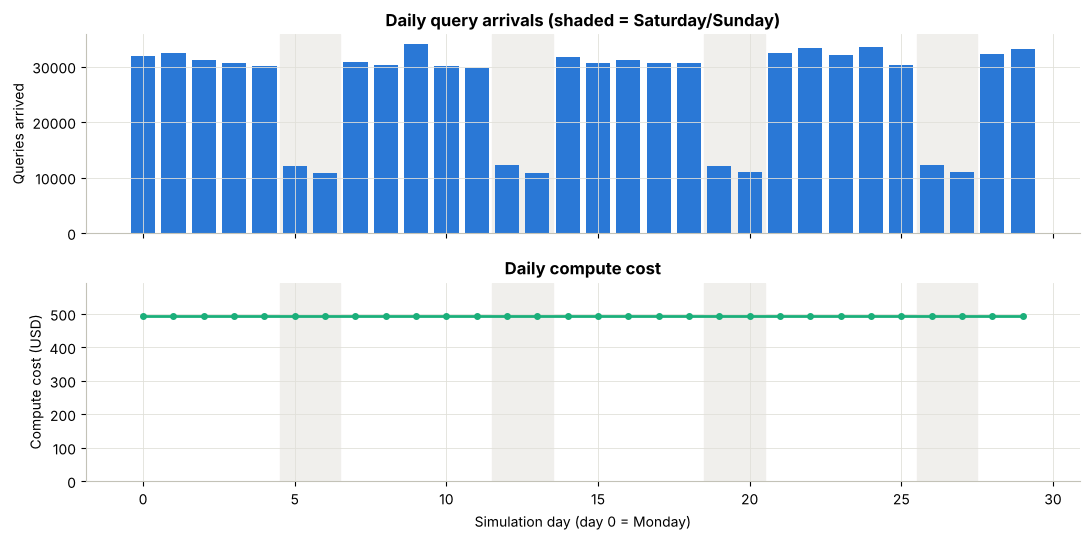

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
weekend = [d for d in full_days.index if d % 7 in (5, 6)]
for ax in (ax1, ax2):
    for d in weekend:
        ax.axvspan(d - 0.5, d + 0.5, color="#f0efec", zorder=0)
ax1.bar(full_days.index, full_days["arrivals"], color="#2a78d6", width=0.8)
ax1.set_ylabel("Queries arrived")
ax1.set_title("Daily query arrivals (shaded = Saturday/Sunday)")
ax2.plot(full_days.index, full_days["total"], color="#1baf7a", marker="o", markersize=4)
ax2.set_ylim(0, full_days["total"].max() * 1.2)
ax2.set_ylabel("Compute cost (USD)")
ax2.set_title("Daily compute cost")
ax2.set_xlabel("Simulation day (day 0 = Monday)")
plt.tight_layout()
plt.show()

The top panel drops sharply every weekend (the shaded days), while the bottom panel is a flat line. I left out day 30 because it is a partial day.

## 7. Unusual or unexpected billing patterns

Here I summarise anything in the bill that a reader might not expect.

In [14]:
anomalies = {
    "markets used": sorted(bill["market"].unique()),
    "days with a cost different from the most common daily cost":
        daily.index[daily["total"].round(2) != daily["total"].round(2).mode()[0]].tolist(),
    "rows not matching config price": int((bill["reconciliation_diff"].abs() >= 1e-3).sum()),
    "seconds billed after the 30-day contract period":
        round(float(hours_covered.loc[hours_covered.index >= config["duration_s"] // 86400].sum() * 3600), 1),
    "cost after the 30-day contract period (USD)":
        round(float(daily.loc[daily.index >= config["duration_s"] // 86400, "total"].sum()), 2),
}
for k, v in anomalies.items():
    print(f"{k}: {v}")

markets used: ['on_demand']
days with a cost different from the most common daily cost: [30]
rows not matching config price: 0
seconds billed after the 30-day contract period: 9000.0
cost after the 30-day contract period (USD): 51.5


There were four things worth pointing out:

1. **There was no spot usage at all.** This was a big missed saving, and it also means there is no historical evidence about spot.
2. **Only day 30 is different** from the usual \$494.40, because it is a 2.5-hour partial day.
3. **There were no pricing anomalies.** Every row matches the config.
4. **9,000 seconds (\$51.50) were billed after the 30-day period**, because the simulator keeps running until all waiting and running queries are finished. A scheduler should expect this end-of-month tail and release machines as soon as their work is done.

## 8. Summary of findings

**What I observed**

- The total compute spend was **\$14,883.50** for **10,115 instance-hours**, all on-demand.
- The fleet was **2 `std.small`, 6 `std.large` and 6 `mem.xlarge`** machines, and it did not change for the whole run.
- `mem.xlarge` took about 79% of the bill, `std.large` about 20%, and `std.small` less than 1%.
- Each full day cost **\$494.40** (\$20.60 per hour \* 24), plus **\$51.50** for a 2.5-hour tail on day 30.
- Daily arrivals varied by about 3 times (about 30k to 34k on weekdays and about 11k to 12k at weekends), but the cost did not change at all.

**How I interpret this**

- The fleet was sized once and never adjusted. Nights and weekends were paid for at the same rate as weekday peaks.
- Most of the money went to the `mem.xlarge` pool. Scaling it with demand, moving part of it to spot, or both, are the biggest savings available.

**Limitations**

- The bill only shows money and machine-hours. It does not show whether the machines were busy. To measure idle cost, I need the instance log (Notebook 2).
- There is no spot data, so I cannot estimate spot risk from the history.
- The number of arrivals is only a rough measure of work, because query types have very different runtimes.

**What this means for the scheduler:** the cost should follow demand. The scheduler needs to scale each machine pool up and down over the day and the week, and it should consider spot for work that can handle interruptions or has plenty of spare time before its deadline.